
# ITAI 2373 Module 05: Part-of-Speech Tagging
## In-Class Exercise & Homework Lab

Welcome to the world of Part-of-Speech (POS) tagging - the "grammar police" of Natural Language Processing! 🚔📝

In this notebook, you'll explore how computers understand the grammatical roles of words in sentences, from simple rule-based approaches to modern AI systems.

### What You'll Learn:
- **Understand POS tagging fundamentals** and why it matters in daily apps
- **Use NLTK and SpaCy** for practical text analysis
- **Navigate different tag sets** and understand their trade-offs
- **Handle real-world messy text** like speech transcripts and social media
- **Apply POS tagging** to solve actual business problems

### Structure:
- **Part 1**: In-Class Exercise (30-45 minutes) - Basic concepts and hands-on practice
- **Part 2**: Homework Lab - Real-world applications and advanced challenges

---

*💡 **Pro Tip**: POS tagging is everywhere! It helps search engines understand "Apple stock" vs "apple pie", helps Siri understand your commands, and powers autocorrect on your phone.*



## 🛠️ Setup and Installation

Let's get our tools ready! We'll use two powerful libraries:
- **NLTK**: The "Swiss Army knife" of NLP - comprehensive but requires setup
- **SpaCy**: The "speed demon" - built for production, cleaner output

Run the cells below to install and set up everything we need.


In [1]:

# Install required libraries (run this first!)
!pip install nltk spacy matplotlib seaborn pandas
!python -m spacy download en_core_web_sm

print("✅ Installation complete!")


     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     ------------- -------------------------- 4.2/12.8 MB 18.0 MB/s eta 0:00:01
     ----------------- ---------------------- 5.5/12.8 MB 19.0 MB/s eta 0:00:01
     ---------------------- ----------------- 7.3/12.8 MB 12.0 MB/s eta 0:00:01
     ---------------------- ----------------- 7.3/12.8 MB 12.0 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 13.2 MB/s  0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
✅ Installation complete!


In [9]:

# Import all the libraries we'll need
import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Download NLTK data (this might take a moment)
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('universal_tagset')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('punkt_tab') 

# Load SpaCy model
nlp = spacy.load('en_core_web_sm')

print("🎉 All libraries loaded successfully!")
print("📚 NLTK version:", nltk.__version__)
print("🚀 SpaCy version:", spacy.__version__)


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\rfox\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\rfox\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package universal_tagset to
[nltk_data]     C:\Users\rfox\AppData\Roaming\nltk_data...
[nltk_data]   Package universal_tagset is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\rfox\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\rfox\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


🎉 All libraries loaded successfully!
📚 NLTK version: 3.9.2
🚀 SpaCy version: 3.8.15



---
# 🎯 PART 1: IN-CLASS EXERCISE (30-45 minutes)

Welcome to the hands-on portion! We'll start with the basics and build up your understanding step by step.

## Learning Goals for Part 1:
1. Understand what POS tagging does
2. Use NLTK and SpaCy for basic tagging
3. Interpret and compare different tag outputs
4. Explore word ambiguity with real examples
5. Compare different tagging approaches



## 🔍 Activity 1: Your First POS Tags (10 minutes)

Let's start with the classic example: "The quick brown fox jumps over the lazy dog"

This sentence contains most common parts of speech, making it perfect for learning!


In [10]:

# Let's start with a classic example
sentence = "The quick brown fox jumps over the lazy dog"

# TODO: Use NLTK to tokenize and tag the sentence
# Hint: Use nltk.word_tokenize() and nltk.pos_tag()
tokens = nltk.word_tokenize(sentence)

pos_tags = nltk.pos_tag(tokens)

print("Original sentence:", sentence)
print("\nTokens:", tokens)
print("\nPOS Tags:")
for word, tag in pos_tags:
    print(f"  {word:8} -> {tag}")


Original sentence: The quick brown fox jumps over the lazy dog

Tokens: ['The', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']

POS Tags:
  The      -> DT
  quick    -> JJ
  brown    -> NN
  fox      -> NN
  jumps    -> VBZ
  over     -> IN
  the      -> DT
  lazy     -> JJ
  dog      -> NN



### 🤔 Quick Questions:
1. What does 'DT' mean? What about 'JJ'?
DT = Determiner
JJ = Adjectives
2. Why do you think 'brown' and 'lazy' have the same tag?
They don't have the same tag... Lazy is marked a JJ, Brown is marked as NN, even though it should be JJ
3. Can you guess what 'VBZ' represents?
Verb.

*Hint: Think about the grammatical role each word plays in the sentence!*



## 🚀 Activity 2: SpaCy vs NLTK Showdown (10 minutes)

Now let's see how SpaCy handles the same sentence. SpaCy uses cleaner, more intuitive tag names.


In [11]:

# TODO: Process the same sentence with SpaCy
# Hint: Use nlp(sentence) and access .text and .pos_ attributes
doc = nlp(sentence)

print("SpaCy POS Tags:")
for token in doc:
    print(f"  {token.text:8} -> {token.pos_:6} ({token.tag_})")

print("\n" + "="*50)
print("COMPARISON:")
print("="*50)

# Let's compare side by side
nltk_tags = nltk.pos_tag(nltk.word_tokenize(sentence))
spacy_doc = nlp(sentence)

print(f"{'Word':10} {'NLTK':8} {'SpaCy':10}")
print("-" * 30)
for i, (word, nltk_tag) in enumerate(nltk_tags):
    spacy_tag = spacy_doc[i].pos_
    print(f"{word:10} {nltk_tag:8} {spacy_tag:10}")


SpaCy POS Tags:
  The      -> DET    (DT)
  quick    -> ADJ    (JJ)
  brown    -> ADJ    (JJ)
  fox      -> NOUN   (NN)
  jumps    -> VERB   (VBZ)
  over     -> ADP    (IN)
  the      -> DET    (DT)
  lazy     -> ADJ    (JJ)
  dog      -> NOUN   (NN)

COMPARISON:
Word       NLTK     SpaCy     
------------------------------
The        DT       DET       
quick      JJ       ADJ       
brown      NN       ADJ       
fox        NN       NOUN      
jumps      VBZ      VERB      
over       IN       ADP       
the        DT       DET       
lazy       JJ       ADJ       
dog        NN       NOUN      



### 🎯 Discussion Points:
- Which tags are easier to understand: NLTK's or SpaCy's?
SpaCy is easier, I had to lookup what the NKTK tags ment.
- Do you notice any differences in how they tag the same words?
Yes, brown changes from a noun in NLTK to an adjetive in SpaCy.
- Which system would you prefer for a beginner? Why?
I am liking SpaCy bettwe as it is looking to be more accurate and easier tags to understand.


## 🎭 Activity 3: The Ambiguity Challenge (15 minutes)

Here's where things get interesting! Many words can be different parts of speech depending on context. Let's explore this with some tricky examples.


In [15]:

# Ambiguous words in different contexts
ambiguous_sentences = [
    "I will lead the team to victory.",           # lead = verb
    "The lead pipe is heavy.",                    # lead = noun (metal)
    "She took the lead in the race.",            # lead = noun (position)
    "The bank approved my loan.",                # bank = noun (financial)
    "We sat by the river bank.",                 # bank = noun (shore)
    "I bank with Chase.",                        # bank = verb
    "I read a book.",
    "Please book a flight.",
    "Birds fly south.", 
    "A fly landed on the table.",
    "Light the candle.", 
    "The box is light.", 
    "Close the door.", 
    "The store is close to home.", 
]

print("🎭 AMBIGUITY EXPLORATION")
print("=" * 40)

for sentence in ambiguous_sentences:
    print(f"\nSentence: {sentence}")

    # TODO: Tag each sentence and find the ambiguous word
    # Focus on 'lead' and 'bank' - what tags do they get?
    tokens = nltk.word_tokenize(sentence)
    tags = nltk.pos_tag(tokens)

    # Find and highlight the key word
    for word, tag in tags:
        if word.lower() in ['lead', 'bank', 'read', 'book', 'fly', 'light', 'close']:
            print(f"  🎯 '{word}' is tagged as: {tag}")


🎭 AMBIGUITY EXPLORATION

Sentence: I will lead the team to victory.
  🎯 'lead' is tagged as: VB

Sentence: The lead pipe is heavy.
  🎯 'lead' is tagged as: NN

Sentence: She took the lead in the race.
  🎯 'lead' is tagged as: NN

Sentence: The bank approved my loan.
  🎯 'bank' is tagged as: NN

Sentence: We sat by the river bank.
  🎯 'bank' is tagged as: NN

Sentence: I bank with Chase.
  🎯 'bank' is tagged as: NN

Sentence: I read a book.
  🎯 'read' is tagged as: VBP
  🎯 'book' is tagged as: NN

Sentence: Please book a flight.
  🎯 'book' is tagged as: NN

Sentence: Birds fly south.
  🎯 'fly' is tagged as: VBP

Sentence: A fly landed on the table.
  🎯 'fly' is tagged as: NN

Sentence: Light the candle.
  🎯 'Light' is tagged as: NNP

Sentence: The box is light.
  🎯 'light' is tagged as: JJ

Sentence: Close the door.
  🎯 'Close' is tagged as: RB

Sentence: The store is close to home.
  🎯 'close' is tagged as: JJ



### 🧠 Think About It:
1. How does the computer know the difference between "lead" (metal) and "lead" (guide)?
It has to look at the context in which the word is being used and then is able to identify the difference.

2. What clues in the sentence help determine the correct part of speech?
The words around an ambiguous word are the biggest clues. A modal like "will" or the word "to" right before it usually means it's a verb ("I will lead"). A determiner like "the," "a," or "my" usually means it's a noun ("the lead," "the bank"). A pronoun subject like "I" or "she" right before it points to a verb, and a noun right after it means the word is probably describing that noun ("lead pipe"). Sentence structure also helps: every sentence needs a main verb, so if there's no other verb, the ambiguous word is likely it.

3. Can you think of other words that change meaning based on context?
Yes, and skipping over curse words which almost all have multiple meanings based on context, I can think of run, fly, park, watch, light, close, record, fine

**Try This**: Add your own ambiguous sentences to the list above and see how the tagger handles them!



## 📊 Activity 4: Tag Set Showdown (10 minutes)

NLTK can use different tag sets. Let's compare the detailed Penn Treebank tags (~45 tags) with the simpler Universal Dependencies tags (~17 tags).


In [17]:

# Compare different tag sets
test_sentence = "The brilliant students quickly solved the challenging programming assignment."

# TODO: Get tags using both Penn Treebank and Universal tagsets
# Hint: Use tagset='universal' parameter for universal tags
penn_tags = nltk.pos_tag(nltk.word_tokenize(test_sentence))
universal_tags = nltk.pos_tag(nltk.word_tokenize(test_sentence), tagset='universal')

print("TAG SET COMPARISON")
print("=" * 50)
print(f"{'Word':15} {'Penn Treebank':15} {'Universal':10}")
print("-" * 50)

# TODO: Print comparison table
# Hint: Zip the two tag lists together
for (word, penn_tag), (_, univ_tag) in zip(penn_tags, universal_tags):
    print(f"{word:15} {penn_tag:15} {univ_tag:10}")

# Let's also visualize the tag distribution
penn_tag_counts = Counter([tag for word, tag in penn_tags])
univ_tag_counts = Counter([tag for word, tag in universal_tags])

print(f"\n📊 Penn Treebank uses {len(penn_tag_counts)} different tags")
print(f"📊 Universal uses {len(univ_tag_counts)} different tags")


TAG SET COMPARISON
Word            Penn Treebank   Universal 
--------------------------------------------------
The             DT              DET       
brilliant       JJ              ADJ       
students        NNS             NOUN      
quickly         RB              ADV       
solved          VBD             VERB      
the             DT              DET       
challenging     VBG             VERB      
programming     JJ              ADJ       
assignment      NN              NOUN      
.               .               .         

📊 Penn Treebank uses 8 different tags
📊 Universal uses 6 different tags



### 🤔 Reflection Questions:
1. Which tag set is more detailed? Which is simpler? Enter your answer below

Penn is more detailed because it has more tags. Unversal is simpler because it has easier to understand tage.

2. When might you want detailed tags vs. simple tags? Enter your answer below

Detailed tags (Penn Treebank) are useful when you need to know how a word is being used, not just what kind of word it is. For example, Penn tells apart "solved" (past tense, VBD), "solves" (present, VBZ), and "solving" (-ing form, VBG). That matters for grammar checking, translation, and figuring out when something happened. It also separates singular and plural nouns (NN vs. NNS), which helps with subject-verb agreement.

Simple tags (Universal) are better when you only need the big picture: which words are nouns, verbs, and adjectives. They're easier to read and work across many languages, since every language has nouns and verbs but not all of them have English-style verb endings. Simple tags are also a good choice when you have less training data, because fewer categories means fewer chances for the tagger to guess wrong.

3. If you were building a search engine, which would you choose? Why? Enter your answer below

I'd choose Universal tags. A search engine mostly cares about finding the important words in a query, usually nouns, verbs, and adjectives, and matching them to documents. Whether a verb is past or present tense usually doesn't matter. Someone searching "solved programming assignment" wants the same results as "solve programming assignments." The search engine would already reduce words to a base form (solved → solve) for matching, so the extra detail in Penn tags wouldn't help much.

---



---
# 🎓 End of Part 1: In-Class Exercise

Great work! You've learned the fundamentals of POS tagging and gotten hands-on experience with both NLTK and SpaCy.

## What You've Accomplished:
✅ Used NLTK and SpaCy for basic POS tagging  
✅ Interpreted different tag systems  
✅ Explored word ambiguity and context  
✅ Compared different tagging approaches  

## 🏠 Ready for Part 2?
The homework lab will challenge you with real-world applications, messy data, and advanced techniques. You'll analyze customer service transcripts, handle informal language, and benchmark different taggers.

**Take a break, then dive into Part 2 when you're ready!**

---



# 🏠 PART 2: HOMEWORK LAB
## Real-World POS Tagging Challenges

Welcome to the advanced section! Here you'll tackle the messy, complex world of real text data. This is where POS tagging gets interesting (and challenging)!

## Learning Goals for Part 2:
1. Process real-world, messy text data
2. Handle speech transcripts and informal language
3. Analyze customer service scenarios
4. Benchmark and compare different taggers
5. Understand limitations and edge cases

## 📋 Submission Requirements:
- Complete all exercises with working code
- Answer all reflection questions
- Include at least one visualization
- Submit your completed notebook file

---



## 🌍 Lab Exercise 1: Messy Text Challenge (25 minutes)

Real-world text is nothing like textbook examples! Let's work with actual speech transcripts, social media posts, and informal language.


In [22]:

# Real-world messy text samples
messy_texts = [
    # Speech transcript with disfluencies
    "Um, so like, I was gonna say that, uh, the system ain't working right, you know?",

    # Social media style
    "OMG this app is sooo buggy rn 😤 cant even login smh",

    # Customer service transcript
    "Yeah hi um I'm calling because my internet's been down since like yesterday and I've tried unplugging the router thingy but it's still not working",

    # Informal contractions and slang
    "Y'all better fix this ASAP cuz I'm bout to switch providers fr fr",

    # Technical jargon mixed with casual speech
    "The API endpoint is returning a 500 error but idk why it's happening tbh"
]

print("🔍 PROCESSING MESSY TEXT")
print("=" * 60)

# TODO: Process each messy text sample
# 1. Use both NLTK and SpaCy
# 2. Count how many words each tagger fails to recognize properly
# 3. Identify problematic words (slang, contractions, etc.)

for i, text in enumerate(messy_texts, 1):
    print(f"\n📝 Sample {i}: {text}")
    print("-" * 40)

    # NLTK processing
    nltk_tokens = nltk.word_tokenize(text)
    nltk_tags = nltk.pos_tag(nltk_tokens)

    # TODO: SpaCy processing
    spacy_doc = nlp(text)

    # TODO: Find problematic words (tagged as 'X' or unknown)
    problematic_nltk = [word for word, tag in nltk_tags if nltk.map_tag('en-ptb', 'universal', tag) == 'X']
    problematic_spacy = [tok.text for tok in spacy_doc if tok.pos_ == 'X' or tok.tag_ == 'XX']


    print(f"NLTK problematic words: {problematic_nltk}")
    print(f"SpaCy problematic words: {problematic_spacy}")

    # TODO: Calculate success rate
    nltk_success_rate = (len(nltk_tokens) - len(problematic_nltk)) / len(nltk_tokens)
    spacy_success_rate = (len(spacy_doc) - len(problematic_spacy)) / len(spacy_doc)

    print(f"NLTK success rate: {nltk_success_rate:.1%}")
    print(f"SpaCy success rate: {spacy_success_rate:.1%}")



🔍 PROCESSING MESSY TEXT

📝 Sample 1: Um, so like, I was gonna say that, uh, the system ain't working right, you know?
----------------------------------------
NLTK problematic words: ['uh']
SpaCy problematic words: []
NLTK success rate: 95.8%
SpaCy success rate: 100.0%

📝 Sample 2: OMG this app is sooo buggy rn 😤 cant even login smh
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy success rate: 100.0%

📝 Sample 3: Yeah hi um I'm calling because my internet's been down since like yesterday and I've tried unplugging the router thingy but it's still not working
----------------------------------------
NLTK problematic words: ['Yeah']
SpaCy problematic words: []
NLTK success rate: 96.6%
SpaCy success rate: 100.0%

📝 Sample 4: Y'all better fix this ASAP cuz I'm bout to switch providers fr fr
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
S


### 🎯 Analysis Questions:
1. Which tagger handles informal language better?

SpaCy handles informal language better, but not by much. NLTK had an issue with a few slang words.

2. What types of words cause the most problems?

Slang words and unterjections seamed to cause the most probelms. 

3. How might you preprocess text to improve tagging accuracy?

- Expand slang and abbreviations ("idk" → "I don't know," "rn" → "right now")
- Replace informal contractions ("gonna" → "going to," "ain't" → "is not")
- Shorten stretched words ("sooo" → "so")
- Remove filler words ("um," "uh") and emoji, or replace emoji with words
- Fix spelling and capitalization

4. What are the implications for real-world applications?

- **Hidden errors:** Taggers don't flag slang as unknown. They quietly guess wrong, so mistakes pass through without anyone noticing.
- **Errors carry forward:** Wrong tags hurt everything built on top of them, like chatbots, search, sentiment analysis, and customer service tools.
- **Uneven results:** Tools work worse for people who write casually or use slang or dialects, which can make them less fair.
- **Lost meaning:** Cleaning up text can remove tone, like frustration in "smh" or 😤, which matters for things like customer complaints.



## 📞 Lab Exercise 2: Customer Service Analysis Case Study (30 minutes)

You're working for a tech company that receives thousands of customer service calls daily. Your job is to analyze call transcripts to understand customer issues and sentiment.

**Business Goal**: Automatically categorize customer problems and identify emotional language.


In [26]:

# Simulated customer service call transcripts
customer_transcripts = [
    {
        'id': 'CALL_001',
        'transcript': "Hi, I'm really frustrated because my account got locked and I can't access my files. I've been trying for hours and nothing works. This is completely unacceptable.",
        'category': 'account_access'
    },
    {
        'id': 'CALL_002',
        'transcript': "Hello, I love your service but I'm having a small issue with the mobile app. It crashes whenever I try to upload photos. Could you please help me fix this?",
        'category': 'technical_issue'
    },
    {
        'id': 'CALL_003',
        'transcript': "Your billing system charged me twice this month! I want a refund immediately. This is ridiculous and I'm considering canceling my subscription.",
        'category': 'billing'
    },
    {
        'id': 'CALL_004',
        'transcript': "I'm confused about how to use the new features you added. The interface changed and I can't find anything. Can someone walk me through it?",
        'category': 'user_guidance'
    }
]

# TODO: Analyze each transcript for:
# 1. Emotional language (adjectives that indicate sentiment)
# 2. Action words (verbs that indicate what customer wants)
# 3. Problem indicators (nouns related to issues)

analysis_results = []

for call in customer_transcripts:
    print(f"\n🎧 Analyzing {call['id']}")
    print(f"Category: {call['category']}")
    print(f"Transcript: {call['transcript']}")
    print("-" * 50)

    # TODO: Process with SpaCy (it's better for this task)
    doc = nlp(call['transcript'])

    # TODO: Extract different types of words
    emotional_adjectives = [token.text for token in doc if token.pos_ == "ADJ"]
    action_verbs = [token.text for token in doc if token.pos_ == "VERB" and token.dep_ == "ROOT"]
    problem_nouns = [token.text for token in doc if token.pos_ == "NOUN" and token.dep_ == "dobj"]


    # TODO: Calculate sentiment indicators
    positive_words = [token.text for token in doc if token.lemma_.lower() in ['love', 'great', 'good', 'happy', 'thank', 'thanks', 'appreciate', 'excellent', 'helpful']]
    negative_words = [token.text for token in doc if token.lemma_.lower() in ['frustrated', 'frustrate', 'unacceptable', 'ridiculous', 'confused', 'confuse', 'crash', 'lock', 'cancel', 'angry', 'terrible', 'disappointed']]

    result = {
        'call_id': call['id'],
        'category': call['category'],
        'emotional_adjectives': emotional_adjectives,
        'action_verbs': action_verbs,
        'problem_nouns': problem_nouns,
        'sentiment_score': len(positive_words) - len(negative_words),
        'urgency_indicators': len([word for word in doc if word.text.lower() in ['immediately', 'urgent', 'asap', 'now']])
    }

    analysis_results.append(result)

    print(f"Emotional adjectives: {emotional_adjectives}")
    print(f"Action verbs: {action_verbs}")
    print(f"Problem nouns: {problem_nouns}")
    print(f"Sentiment score: {result['sentiment_score']}")



🎧 Analyzing CALL_001
Category: account_access
Transcript: Hi, I'm really frustrated because my account got locked and I can't access my files. I've been trying for hours and nothing works. This is completely unacceptable.
--------------------------------------------------
Emotional adjectives: ['frustrated', 'unacceptable']
Action verbs: ['trying']
Problem nouns: ['files']
Sentiment score: -3

🎧 Analyzing CALL_002
Category: technical_issue
Transcript: Hello, I love your service but I'm having a small issue with the mobile app. It crashes whenever I try to upload photos. Could you please help me fix this?
--------------------------------------------------
Emotional adjectives: ['small', 'mobile']
Action verbs: ['love', 'crashes', 'help']
Problem nouns: ['service', 'issue', 'photos']
Sentiment score: 0

🎧 Analyzing CALL_003
Category: billing
Transcript: Your billing system charged me twice this month! I want a refund immediately. This is ridiculous and I'm considering canceling my subsc

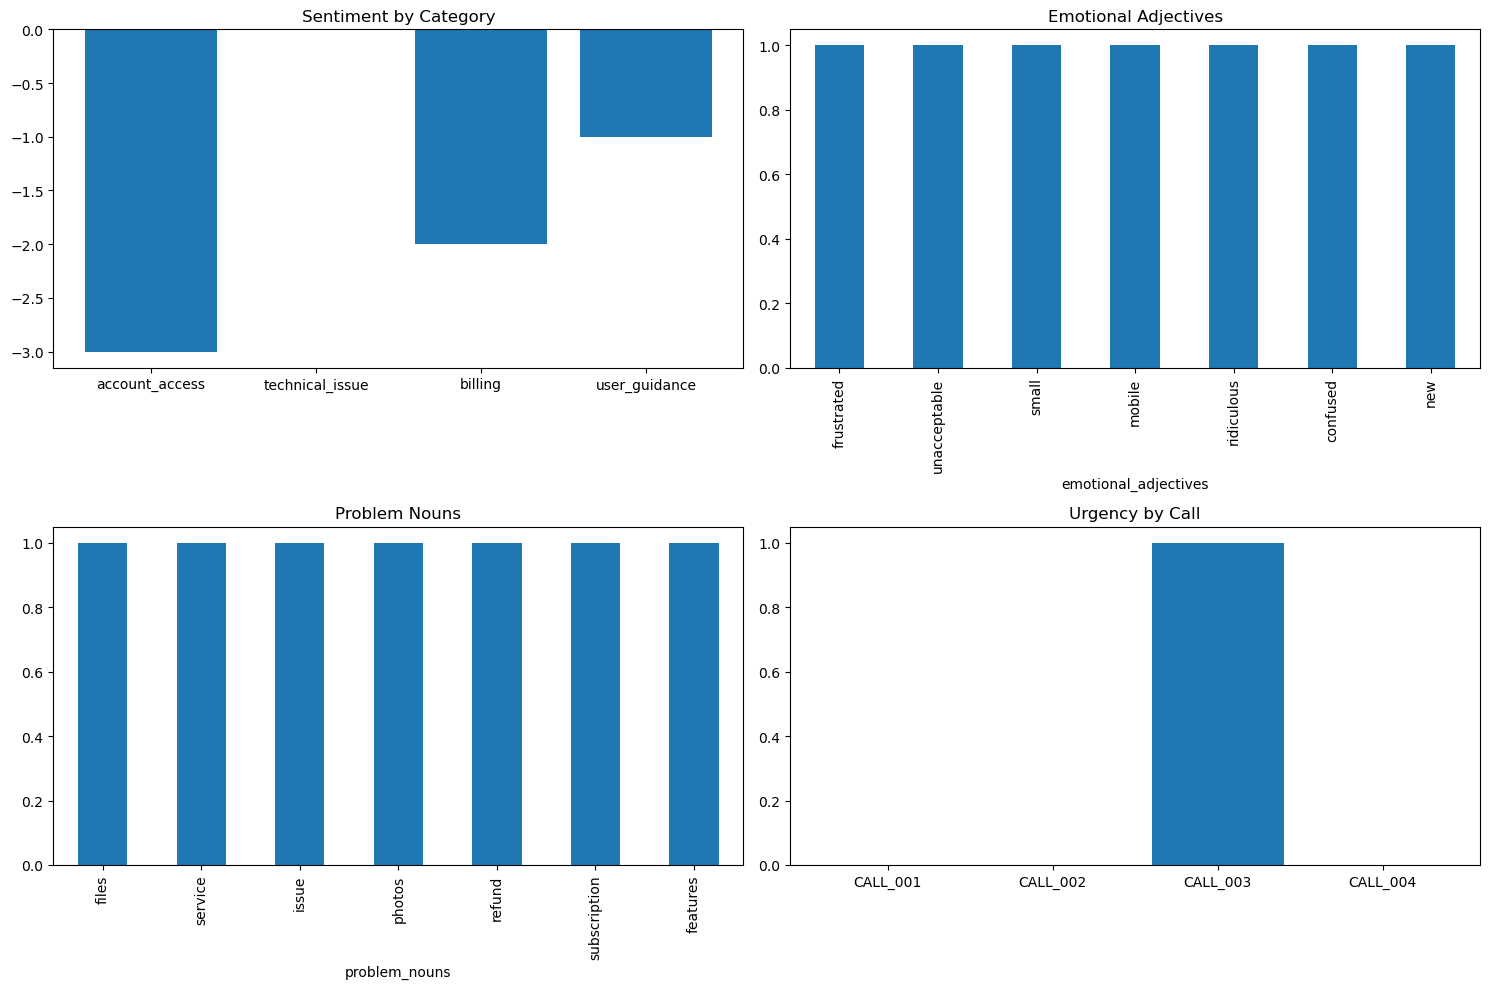

In [27]:

# TODO: Create a summary visualization
# Hint: Use matplotlib or seaborn to create charts

import matplotlib.pyplot as plt
import pandas as pd

# Convert results to DataFrame for easier analysis
df = pd.DataFrame(analysis_results)

# TODO: Create visualizations
# 1. Sentiment scores by category
# 2. Most common emotional adjectives
# 3. Action verbs frequency

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# TODO: Plot 1 - Sentiment by category
axes[0, 0].bar(df['category'], df['sentiment_score'])
axes[0, 0].set_title('Sentiment by Category')

# TODO: Plot 2 - Word frequency analysis
df['emotional_adjectives'].explode().value_counts().plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('Emotional Adjectives')

# TODO: Plot 3 - Problem categorization
df['problem_nouns'].explode().value_counts().plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Problem Nouns')

# TODO: Plot 4 - Urgency analysis
axes[1, 1].bar(df['call_id'], df['urgency_indicators'])
axes[1, 1].set_title('Urgency by Call')

plt.tight_layout()
plt.show()



### 💼 Business Impact Questions:
1. How could this analysis help prioritize customer service tickets?

THis can be used to identfy problem areas and what effects customers the most. 

2. What patterns do you notice in different problem categories?

I notice that technical issues have a lower setiment rating that account issues. 

3. How might you automate the routing of calls based on POS analysis?

I would prioritize account access over other calls as it is usually easy to fix and appears to cause the most frustration with users.

4. What are the limitations of this approach?

DIfferent people have different reactions. A major issue could be received in a calm wording not triggereing anything, while a minor issue could have upset a user and they use words that trigger more flags.


## ⚡ Lab Exercise 3: Tagger Performance Benchmarking (20 minutes)

Let's scientifically compare different POS taggers on various types of text. This will help you understand when to use which tool.



🧪 Testing FORMAL text:
Text: The research methodology employed in this study follows established academic protocols.
------------------------------------------------------------
NLTK Penn time: 0.0002s
NLTK Univ time: 0.0007s
SpaCy time: 0.0048s
NLTK unknown words: 0
SpaCy unknown words: 0

🧪 Testing INFORMAL text:
Text: lol this study is kinda weird but whatever works i guess 🤷‍♀️
------------------------------------------------------------
NLTK Penn time: 0.0001s
NLTK Univ time: 0.0006s
SpaCy time: 0.0059s
NLTK unknown words: 0
SpaCy unknown words: 0

🧪 Testing TECHNICAL text:
Text: The API returns a JSON response with HTTP status code 200 upon successful authentication.
------------------------------------------------------------
NLTK Penn time: 0.0001s
NLTK Univ time: 0.0006s
SpaCy time: 0.0042s
NLTK unknown words: 0
SpaCy unknown words: 0

🧪 Testing CONVERSATIONAL text:
Text: So like, when you click that button thingy, it should totally work, right?
------------------------------

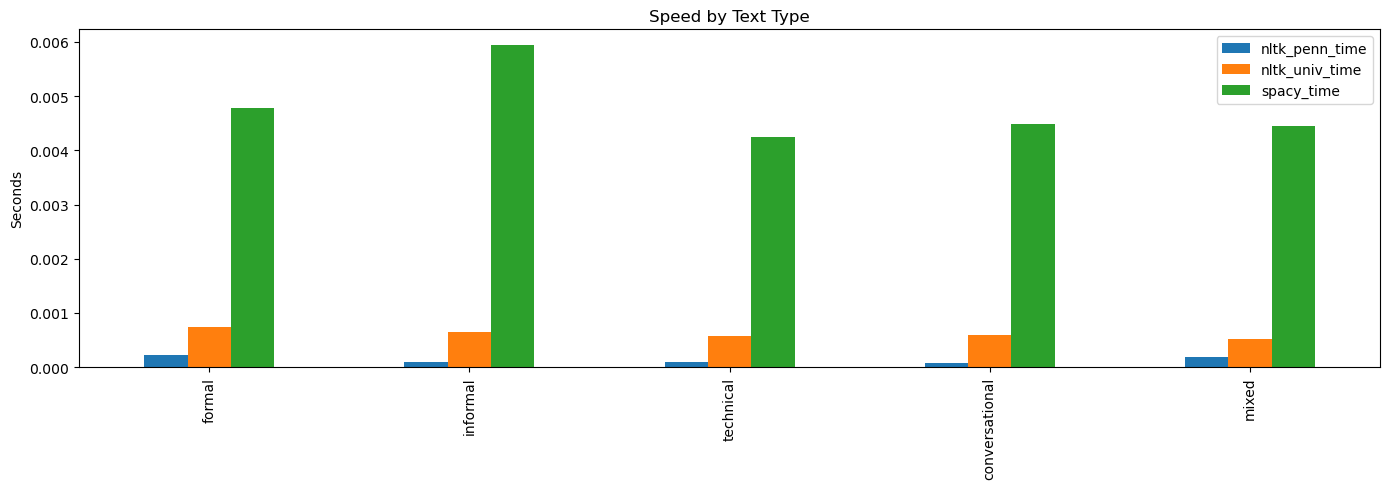

In [35]:

import time
from collections import defaultdict

# Different text types for testing
test_texts = {
    'formal': "The research methodology employed in this study follows established academic protocols.",
    'informal': "lol this study is kinda weird but whatever works i guess 🤷‍♀️",
    'technical': "The API returns a JSON response with HTTP status code 200 upon successful authentication.",
    'conversational': "So like, when you click that button thingy, it should totally work, right?",
    'mixed': "OMG the algorithm's performance is absolutely terrible! The accuracy dropped to 23% wtf"
}

# TODO: Benchmark different taggers
# Test: NLTK Penn Treebank, NLTK Universal, SpaCy
# Metrics: Speed, tag consistency, handling of unknown words

benchmark_results = defaultdict(list)

for text_type, text in test_texts.items():
    print(f"\n🧪 Testing {text_type.upper()} text:")
    print(f"Text: {text}")
    print("-" * 60)

    # TODO: NLTK Penn Treebank timing
    start_time = time.time()
    nltk_tokens = nltk.word_tokenize(text)
    nltk_penn_time = time.time() - start_time

    # TODO: NLTK Universal timing
    start_time = time.time()
    nltk_tokens_univ = nltk.pos_tag(nltk_tokens)
    nltk_univ_time = time.time() - start_time

    # TODO: SpaCy timing
    start_time = time.time()
    spacy_doc = nlp(text)
    spacy_time = time.time() - start_time

    # TODO: Count unknown/problematic tags
    nltk_unknown = len([token for token in nltk_tokens_univ if token[1] == 'X'])
    spacy_unknown = len([token for token in spacy_doc if token.pos_ == 'X'])    

    # Store results
    benchmark_results[text_type] = {
        'nltk_penn_time': nltk_penn_time,
        'nltk_univ_time': nltk_univ_time,
        'spacy_time': spacy_time,
        'nltk_unknown': nltk_unknown,
        'spacy_unknown': spacy_unknown
    }

    print(f"NLTK Penn time: {nltk_penn_time:.4f}s")
    print(f"NLTK Univ time: {nltk_univ_time:.4f}s")
    print(f"SpaCy time: {spacy_time:.4f}s")
    print(f"NLTK unknown words: {nltk_unknown}")
    print(f"SpaCy unknown words: {spacy_unknown}")

# TODO: Create performance comparison visualization
df_bench = pd.DataFrame(benchmark_results).T

fig, axes = plt.subplots(1, 1, figsize=(14, 5))

df_bench[['nltk_penn_time', 'nltk_univ_time', 'spacy_time']].plot(kind='bar', ax=axes)
axes.set_title('Speed by Text Type')
axes.set_ylabel('Seconds')

plt.tight_layout()
plt.show()


### 📊 Performance Analysis:
1. Which tagger is fastest? Does speed matter for your use case?

NLTK Penn time consistantly runs the fastet. For this current use case, speed does not matter because we have a small smaple size.

2. Which handles informal text best?

SpaCy has been handeling informal test best.

3. How do the taggers compare on technical jargon?

I don't see any issues with technical jargon. All taggers worked will.

4. What trade-offs do you see between speed and accuracy?

NLTK performed much faster, but that lost acuracy over SpaCy. SpaCy had easier to understand taggs.


## 🚨 Lab Exercise 4: Edge Cases and Error Analysis (15 minutes)

Every system has limitations. Let's explore the edge cases where POS taggers struggle and understand why.


In [38]:

# Challenging edge cases
edge_cases = [
    "Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.",  # Famous ambiguous sentence
    "Time flies like an arrow; fruit flies like a banana.",              # Classic ambiguity
    "The man the boat the river.",                                       # Garden path sentence
    "Police police Police police police police Police police.",          # Recursive structure
    "James while John had had had had had had had had had had had a better effect on the teacher.",  # Had had had...
    "Can can can can can can can can can can.",                         # Modal/noun ambiguity
    "@username #hashtag http://bit.ly/abc123 😂🔥💯",                   # Social media elements
    "COVID-19 AI/ML IoT APIs RESTful microservices",                    # Modern technical terms
]

print("🚨 EDGE CASE ANALYSIS")
print("=" * 50)

# TODO: Process each edge case and analyze failures
for i, text in enumerate(edge_cases, 1):
    print(f"\n🔍 Edge Case {i}:")
    print(f"Text: {text}")
    print("-" * 30)

    try:
        # TODO: Process with both taggers
        nltk_tags = nltk.pos_tag(nltk.word_tokenize(text))
        spacy_doc = nlp(text)
        
        # TODO: Identify potential errors or weird tags
        # Look for: repeated tags, unusual patterns, X tags, etc.
        nltk_x = [w for w, t in nltk_tags if nltk.map_tag('en-ptb', 'universal', t) == 'X']
        spacy_x = [tok.text for tok in spacy_doc if tok.pos_ == 'X']
        nltk_repeats = [nltk_tags[j][0] for j in range(2, len(nltk_tags)) if nltk_tags[j][1] == nltk_tags[j-1][1] == nltk_tags[j-2][1]]
        spacy_repeats = [spacy_doc[j].text for j in range(2, len(spacy_doc)) if spacy_doc[j].pos_ == spacy_doc[j-1].pos_ == spacy_doc[j-2].pos_]



        print("NLTK tags:", [(w, t) for w, t in nltk_tags])
        print("SpaCy tags:", [(token.text, token.pos_) for token in spacy_doc])

        # TODO: Analyze what went wrong
        # YOUR ANALYSIS CODE HERE
        nltk_has_verb = any(t.startswith('VB') or t == 'MD' for w, t in nltk_tags)
        spacy_has_verb = any(tok.pos_ in ('VERB', 'AUX') for tok in spacy_doc)

    except Exception as e:
        print(f"❌ Error processing: {e}")

# TODO: Reflection on limitations
print("\n🤔 REFLECTION ON LIMITATIONS:")
print("=" * 40)
# YOUR REFLECTION CODE HERE
print("- Taggers guess from nearby words and common patterns. They don't understand meaning,")
print("  so sentences like 'Buffalo buffalo...' come out as a long string of nouns.")
print("- Garden path sentences fool them the same way they fool people, because the first")
print("  reading seems right until the end.")
print("- Repeated words like 'had had had' or 'can can can' get the same tag over and over,")
print("  because the tagger can't track the structure.")
print("- Social media items (@, #, URLs, emoji) and new tech terms get split or tagged")
print("  differently by each tool, since they weren't common in the training data.")
print("- Taggers rarely say 'unknown.' They confidently guess, so errors are easy to miss.")

🚨 EDGE CASE ANALYSIS

🔍 Edge Case 1:
Text: Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.
------------------------------
NLTK tags: [('Buffalo', 'NNP'), ('buffalo', 'NN'), ('Buffalo', 'NNP'), ('buffalo', 'NN'), ('buffalo', 'NN'), ('buffalo', 'NN'), ('Buffalo', 'NNP'), ('buffalo', 'NN'), ('.', '.')]
SpaCy tags: [('Buffalo', 'PROPN'), ('buffalo', 'NOUN'), ('Buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('Buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('.', 'PUNCT')]

🔍 Edge Case 2:
Text: Time flies like an arrow; fruit flies like a banana.
------------------------------
NLTK tags: [('Time', 'NNP'), ('flies', 'NNS'), ('like', 'IN'), ('an', 'DT'), ('arrow', 'NN'), (';', ':'), ('fruit', 'CC'), ('flies', 'NNS'), ('like', 'IN'), ('a', 'DT'), ('banana', 'NN'), ('.', '.')]
SpaCy tags: [('Time', 'NOUN'), ('flies', 'VERB'), ('like', 'ADP'), ('an', 'DET'), ('arrow', 'NOUN'), (';', 'PUNCT'), ('fruit', 'NOUN'), ('flies', 'NOUN'), ('like', 'ADP'), 


### 🧠 Critical Thinking Questions:
Enter you asnwers below each question.
1. Why do these edge cases break the taggers?

These edge cases break the taggers because taggers guess from common patterns and nearby words. They don't understand meaning or full sentence structure.

2. How might you preprocess text to handle some of these issues?

Some of these issues can be handled by cleaning up the text before tagging:

- **Social media:** Replace URLs, @mentions, and hashtags with placeholder tokens like `<URL>`, `<USER>`, and `<HASHTAG>`, so the tokenizer doesn't split them into pieces.
- **Emoji:** Remove them or replace them with words describing them (😂 → "laughing").
- **Tech terms:** Keep a custom list of terms like "COVID-19," "AI/ML," and "RESTful" so they stay as single tokens, and tag them as nouns.
- **Special characters:** Split or join symbols like "/" and "-" consistently, so "AI/ML" is handled the same way every time.


3. When would these limitations matter in real applications?

These limitations matter most when the text is messy or unusual and a wrong tag leads to a bad decision:

- **Social media monitoring:** Posts full of emoji, hashtags, slang, and links get tagged poorly, so brand or sentiment tracking can miss what people are actually saying.
- **Customer service tools:** If a tagger misreads what the customer wants, like confusing a verb for a noun, the request can get sent to the wrong team or answered incorrectly.
- **Technical and medical text:** New terms like "COVID-19" or product names get strange tags, which can hurt search and document analysis in those fields.
- **Voice assistants:** Spoken language is full of fillers and odd sentence structure, so commands can be misunderstood.
- **High-stakes uses:** In legal, medical, or financial text, a tagging error can change the meaning of a sentence, and the tagger won't warn anyone that it guessed.

For casual uses like basic keyword search, small tagging errors usually don't matter much.

4. How do modern large language models handle these cases differently?

Modern large language models (LLMs) handle many of these cases better for a few reasons:

- **They read the whole sentence at once.** Older taggers mostly look at nearby words. LLMs weigh every word against every other word, so they can work out that "flies" is a verb in "Time flies" but a noun in "fruit flies."
- **They're trained on much more varied text.** LLMs learn from social media, forums, chats, and technical writing, not just news articles, so slang like "smh," emoji, and hashtags are familiar.
- **They break unknown words into pieces.** New terms like "RESTful" or "microservices" get split into smaller known parts, so the model can still make a good guess.
- **They don't depend on tags.** LLMs understand meaning directly instead of passing one fixed tag to the next step, so one wrong guess doesn't carry through the rest of the system.

LLMs still have limits. They can struggle with extreme cases like "Buffalo buffalo...," they're much slower and more expensive to run, and they can be confidently wrong without explaining why. For simple, high-volume tasks, a fast traditional tagger is often still the better choice.

---



## 🎯 Final Reflection and Submission

Congratulations! You've completed a comprehensive exploration of POS tagging, from basic concepts to real-world challenges.

### 📝 Reflection Questions (Answer in the cell below):

1. **Tool Comparison**: Based on your experience, when would you choose NLTK vs SpaCy? Consider factors like ease of use, accuracy, speed, and application type.

2. **Real-World Applications**: Describe a specific business problem where POS tagging would be valuable. How would you implement it?

3. **Limitations and Solutions**: What are the biggest limitations you discovered? How might you work around them?

4. **Future Learning**: What aspects of POS tagging would you like to explore further? (Neural approaches, custom training, domain adaptation, etc.)

5. **Integration**: How does POS tagging fit into larger NLP pipelines? What other NLP tasks might benefit from POS information?



### ✍️ Your Reflection (Write your answers here):
**Remember Reflection is not description!**

**1. Tool Comparison:**
Based on this lab, I'd choose based on the job:

**NLTK** is better for learning and experimenting. Each step (tokenizing, tagging, switching tag sets) is separate, so it's easy to see what's happening. It's also lightweight for quick, simple tasks. Setup was more annoying, though: I had to download separate data packages, and a missing one caused my first error.

**spaCy** was more accurate in my tests. It correctly tagged "brown" as an adjective and got both halves of "Time flies like an arrow; fruit flies like a banana" right, where NLTK didn't. It also kept "@username" and URLs whole instead of splitting them. It does more in one step (tagging, parsing, entities), which makes it better for real applications like the customer service analysis. That extra work can make it slower on tiny texts, but it's built to handle large amounts of text efficiently.

**My choice:** I'd use NLTK for teaching, research, or quick tests, and spaCy for production applications where accuracy and a complete pipeline matter.

**2. Real-World Applications:**

**Problem:** A support team gets thousands of messages a day and spends a lot of time reading each one to decide what it's about and how urgent it is.

**How POS tagging helps:** Nouns show the problem (refund, account, app), verbs show what the customer wants (cancel, fix, reset), and adjectives show how they feel (frustrated, confused).

**Implementation:**
1. Clean the text (expand slang, remove emoji and links).
2. Tag each message with spaCy.
3. Use the nouns and verbs to route tickets to the right team.
4. Use the adjectives and urgency words to put upset or urgent customers first.

**Result:** Faster routing and quicker help for unhappy customers.

**3. Limitations and Solutions:**

**Biggest limitations:**
1. **Silent errors:** Taggers rarely mark words as unknown. They confidently guessed wrong on slang like "smh" and "rn," so mistakes were easy to miss.
2. **Messy text:** Slang, emoji, URLs, and filler words got split into odd pieces or given strange tags.
3. **Ambiguity:** Words with more than one role confused the taggers ("I bank with Chase," "Buffalo buffalo...").
4. **Setup issues:** NLTK needed extra data downloads, and spaCy's small model has no word sentiment scores, so the sentiment code returned nothing.

**Workarounds:**
- Clean the text first: expand slang, fix contractions, and replace emoji and links.
- Use spaCy or a model trained on similar text, like social media or chat data.
- Check results against a dictionary or word list to catch words the tagger got wrong.
- For hard cases, use a modern language model that reads the whole sentence.

**4. Future Learning:**

I'd like to explore these areas further:

- **Custom training:** Training a tagger on my own labeled examples, like support tickets or chat messages, to see how much it improves on slang and informal text.
- **Domain adaptation:** Adapting an existing model to a specific field, such as technical or financial language, so it handles terms like "API" or "RESTful" correctly.
- **Neural approaches:** Learning how transformer models like BERT tag words using the whole sentence, and comparing their accuracy against NLTK and spaCy on the edge cases from this lab.
- **Combining with other tools:** Using POS tags together with named entity recognition and sentiment analysis to build a more complete text analysis system.

Custom training interests me most, because the lab showed that the taggers struggle most with the kind of messy text real businesses deal with.

**5. Integration:**

POS tagging is usually an early step in an NLP pipeline. The typical order is:

**Clean text → Tokenize → POS tag → Other tasks (parsing, entities, sentiment, etc.)**

It gives later steps basic grammar information to build on, so an early tagging mistake can cause problems further down the line.

**Tasks that benefit from POS information:**
- **Lemmatization:** Getting a word's base form depends on its role ("saw" as a verb → "see," but as a noun it stays "saw").
- **Dependency parsing:** Figuring out how words relate to each other in a sentence starts with knowing which words are nouns and verbs.
- **Named entity recognition:** Proper noun tags help find names of people, places, and companies.
- **Sentiment analysis:** Adjectives and adverbs carry most of the emotion in text.
- **Keyword extraction and search:** Nouns and verbs usually hold the main topic of a sentence.
- **Machine translation and text-to-speech:** The tag decides the translation or pronunciation ("record" as a noun vs. a verb).
- **Question answering and chatbots:** Verbs show what the user wants done, and nouns show what it's about.



---

## 📤 Submission Checklist

Before submitting your completed notebook, make sure you have:

- [ ] ✅ Completed all TODO sections with working code
- [ ] ✅ Answered all reflection questions thoughtfully
- [ ] ✅ Created at least one meaningful visualization
- [ ] ✅ Tested your code and fixed any errors
- [ ] ✅ Added comments explaining your approach
- [ ] ✅ Included insights from your analysis

### 📋 Submission Instructions:
1. **Save your notebook**: File → Save (or Ctrl+S)
2. **Download**: File → Download → Download .ipynb
3. **Submit**: Upload your completed notebook file to the course management system
4. **Filename**: Use format: `L05_LastName_FirstName_ITAI2373.ipynb or pdf`  

### 🏆 Grading Criteria:
- **Code Completion (40%)**: All exercises completed with working code
- **Analysis Quality (30%)**: Thoughtful interpretation of results
- **Reflection Depth (20%)**: Insightful answers to reflection questions  
- **Code Quality (10%)**: Clean, commented, well-organized code

---

## 🎉 Great Work!

You've successfully explored the fascinating world of POS tagging! You now understand how computers parse human language and can apply these techniques to solve real-world problems.


Keep exploring and happy coding! 🚀
